# **Partie I — Modèle discriminatif**


In [12]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader

from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np

print("PyTorch :", torch.__version__)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device :", device)

PyTorch : 2.14.1+cpu
Device : cpu


# **1. Jeu de données MNIST**

In [13]:
transform = transforms.ToTensor()

train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False)

print("Train :", len(train_dataset))
print("Test  :", len(test_dataset))

Train : 60000
Test  : 10000


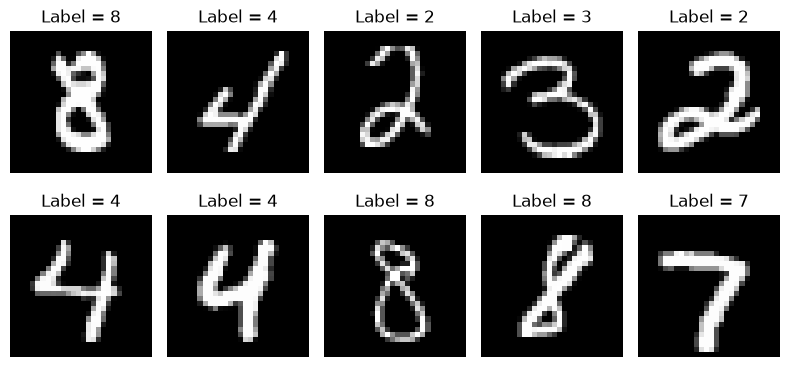

In [14]:
images, labels = next(iter(train_loader))

fig, axes = plt.subplots(2, 5, figsize=(8, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].squeeze(), cmap="gray")
    ax.set_title(f"Label = {labels[i].item()}")
    ax.axis("off")
plt.tight_layout()
plt.show()

# **Partie I — Modèle discriminatif**

# **2. Classification : apprendre \(P(y|x)\)**

Un classifieur reçoit une entrée \(x\) et prédit une classe \(y\).
$$
\
x \longrightarrow \text{Réseau de neurones} \longrightarrow \hat y
\
$$
L'objectif est d'apprendre approximativement :
$$
\
P(y|x)
\
$$
Nous allons utiliser un réseau entièrement connecté simple.

In [15]:
class Classifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.net(x)

classifier = Classifier().to(device)
classifier

Classifier(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)

In [16]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(classifier.parameters(), lr=1e-3)

In [17]:
def train_classifier(model, loader, epochs=3):
    model.train()

    for epoch in range(epochs):
        total_loss = 0

        for x, y in loader:
            x, y = x.to(device), y.to(device)

            logits = model(x)
            loss = criterion(logits, y)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        print(
            f"Epoch {epoch+1}/{epochs} - "
            f"Loss = {total_loss/len(loader):.4f}"
        )

train_classifier(classifier, train_loader, epochs=3)

Epoch 1/3 - Loss = 0.4067
Epoch 2/3 - Loss = 0.1853
Epoch 3/3 - Loss = 0.1339


In [18]:
def evaluate_classifier(model, loader):
    model.eval()

    correct = 0
    total = 0

    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)

            logits = model(x)
            pred = logits.argmax(dim=1)

            correct += (pred == y).sum().item()
            total += y.size(0)

    return correct / total

accuracy = evaluate_classifier(classifier, test_loader)
print(f"Accuracy = {100*accuracy:.2f}%")

Accuracy = 96.39%


In [19]:
from torcheval.metrics import MulticlassAccuracy

@torch.no_grad()
def evaluate_classifier(model, loader):
    model.eval()
    device = next(model.parameters()).device

    metric = MulticlassAccuracy(device=device)

    for x, y in loader:
        x, y = x.to(device), y.to(device)

        logits = model(x)
        metric.update(logits, y)

    return metric.compute().item()


accuracy = evaluate_classifier(classifier, test_loader)
print(f"Accuracy = {100 * accuracy:.2f}%")

Accuracy = 96.39%


# Partie 2 : Autoencoders

In [20]:
class Autoencoder(nn.Module):
    def __init__(self, latent_dim=2):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 32),
            nn.ReLU(),
            nn.Linear(32, latent_dim)
        )

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 32),
            nn.ReLU(),
            nn.Linear(32, 128),
            nn.ReLU(),
            nn.Linear(128, 784),
            nn.Sigmoid()
        )

    def encode(self, x):
        return self.encoder(x)

    def decode(self, z):
        x_hat = self.decoder(z)
        return x_hat.view(-1, 1, 28, 28)

    def forward(self, x):
        z = self.encode(x)
        x_hat = self.decode(z)
        return x_hat

ae = Autoencoder(latent_dim=2).to(device)
ae

Autoencoder(
  (encoder): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=32, bias=True)
    (4): ReLU()
    (5): Linear(in_features=32, out_features=2, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=2, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=784, bias=True)
    (5): Sigmoid()
  )
)

# **4. Loss de reconstruction**

Nous utilisons ici :
$$
\
\mathcal{L}_{rec}=\frac{1}{N}\sum_{i=1}^{N}(x_i-\hat{x}_i)^2
\
$$
avec `MSELoss`.

In [31]:
ae_criterion = nn.MSELoss()
ae_optimizer = torch.optim.Adam(ae.parameters(), lr=1e-3)
def train_autoencoder(model, loader, epochs=10):
    model.train()

    for epoch in range(epochs):
        total_loss = 0

        for x, _ in loader:
            x = x.to(device)

            x_hat = model(x)
            loss = ae_criterion(x_hat, x)

            ae_optimizer.zero_grad()
            loss.backward()
            ae_optimizer.step()

            total_loss += loss.item()

        print(
            f"Epoch {epoch+1}/{epochs} - "
            f"Loss = {total_loss/len(loader):.4f}"
        )

train_autoencoder(ae, train_loader, epochs=16)

Epoch 1/16 - Loss = 0.0384
Epoch 2/16 - Loss = 0.0382
Epoch 3/16 - Loss = 0.0381
Epoch 4/16 - Loss = 0.0380
Epoch 5/16 - Loss = 0.0379
Epoch 6/16 - Loss = 0.0378
Epoch 7/16 - Loss = 0.0378
Epoch 8/16 - Loss = 0.0377
Epoch 9/16 - Loss = 0.0376
Epoch 10/16 - Loss = 0.0375
Epoch 11/16 - Loss = 0.0374
Epoch 12/16 - Loss = 0.0374
Epoch 13/16 - Loss = 0.0373
Epoch 14/16 - Loss = 0.0373
Epoch 15/16 - Loss = 0.0372
Epoch 16/16 - Loss = 0.0371


# 5. Visualisation des reconstructions

La première ligne montre les images originales.

La deuxième ligne montre les images reconstruites.

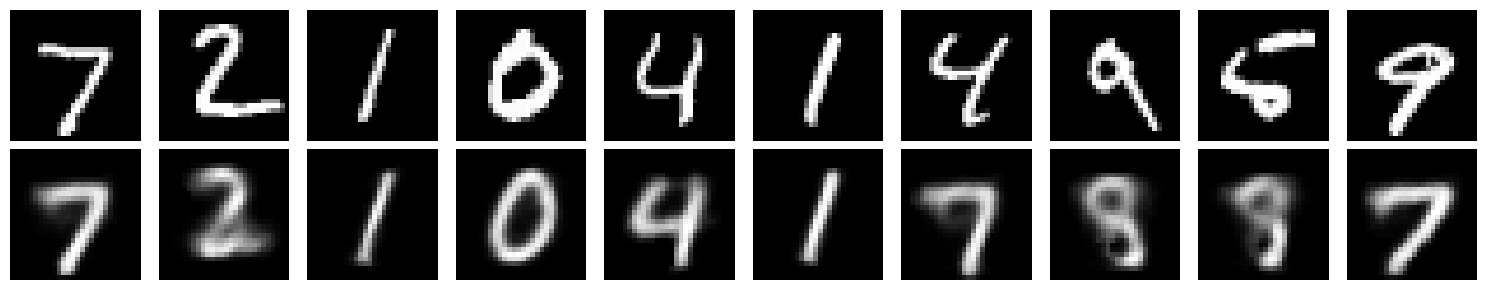

In [32]:
ae.eval()

x, _ = next(iter(test_loader))
x = x[:10].to(device)

with torch.no_grad():
    x_hat = ae(x)

fig, axes = plt.subplots(2, 10, figsize=(15, 3))

for i in range(10):
    axes[0, i].imshow(x[i].cpu().squeeze(), cmap="gray")
    axes[0, i].axis("off")

    axes[1, i].imshow(x_hat[i].cpu().squeeze(), cmap="gray")
    axes[1, i].axis("off")

axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("Reconstruit")

plt.tight_layout()
plt.show()

# **6. Visualisation de l'espace latent**
Nous avons volontairement choisi :

```python
latent_dim = 2
```

Nous pouvons donc représenter chaque image MNIST par un point dans un plan.

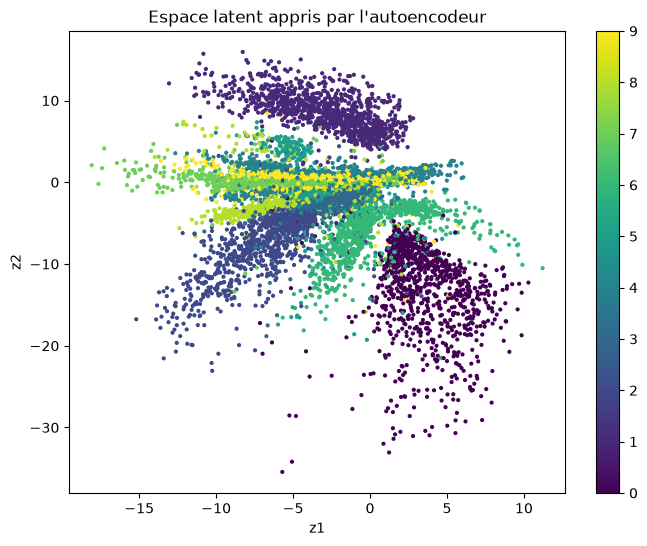

In [33]:
## Visualisation de l'espace latent
ae.eval()

zs = []
ys = []

with torch.no_grad():
    for x, y in test_loader:
        x = x.to(device)
        z = ae.encode(x)

        zs.append(z.cpu())
        ys.append(y)

Z = torch.cat(zs).numpy()
Y = torch.cat(ys).numpy()

plt.figure(figsize=(8, 6))
scatter = plt.scatter(Z[:, 0], Z[:, 1], c=Y, s=4)
plt.xlabel("z1")
plt.ylabel("z2")
plt.title("Espace latent appris par l'autoencodeur")
plt.colorbar(scatter)
plt.show()

## Génération à partir d'un chiffre connu




In [35]:
import torch
import matplotlib.pyplot as plt

@torch.no_grad()
def generer_chiffre(model, dataloader, chiffre):
    if chiffre not in range(10):
        raise ValueError("Le chiffre doit être compris entre 0 et 9.")

    device = next(model.parameters()).device
    model.eval()

    somme_z = None
    nombre = 0

    for images, labels in dataloader:
        # Sélection des images du chiffre demandé
        images = images[labels == chiffre]

        if images.shape[0] == 0:
            continue

        z = model.encode(images.to(device))

        if somme_z is None:
            somme_z = z.sum(dim=0, keepdim=True)
        else:
            somme_z += z.sum(dim=0, keepdim=True)

        nombre += z.shape[0]

    if nombre == 0:
        raise ValueError(f"Aucune image du chiffre {chiffre} trouvée.")

    z_moyen = somme_z / nombre
    return model.decode(z_moyen).cpu()

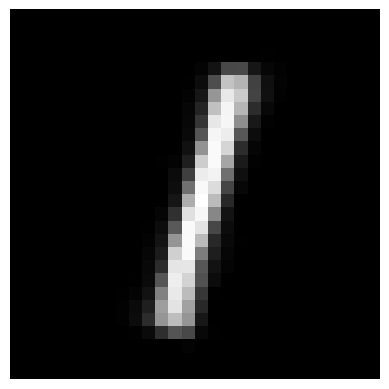

In [36]:
# model : ton autoencodeur entraîné
# train_loader : ton DataLoader MNIST
image = generer_chiffre(ae, train_loader, chiffre=1)

plt.imshow(image[0, 0].numpy(), cmap="gray")
plt.axis("off")
plt.show()

# Partie III — Variational Autoencoder (VAE)

# Reparameterization trick

In [39]:
class VAE(nn.Module):
    def __init__(self, latent_dim=2):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, 64),
            nn.ReLU()
        )

        self.fc_mu = nn.Linear(64, latent_dim)
        self.fc_logvar = nn.Linear(64, latent_dim)

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid()
        )

    def encode(self, x):
        h = self.encoder(x)
        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)
        return mu, logvar

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + std * eps

    def decode(self, z):
        x_hat = self.decoder(z)
        return x_hat.view(-1, 1, 28, 28)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        x_hat = self.decode(z)
        return x_hat, mu, logvar

vae = VAE(latent_dim=2).to(device)
vae

VAE(
  (encoder): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=64, bias=True)
    (4): ReLU()
  )
  (fc_mu): Linear(in_features=64, out_features=2, bias=True)
  (fc_logvar): Linear(in_features=64, out_features=2, bias=True)
  (decoder): Sequential(
    (0): Linear(in_features=2, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=784, bias=True)
    (5): Sigmoid()
  )
)

# Loss et entrainement du VAE

In [40]:
def vae_loss(x_hat, x, mu, logvar, beta=1.0):
    rec_loss = F.binary_cross_entropy(
        x_hat,
        x,
        reduction="sum"
    )

    kl_loss = -0.5 * torch.sum(
        1 + logvar - mu.pow(2) - logvar.exp()
    )

    return rec_loss + beta * kl_loss, rec_loss, kl_loss

In [41]:
## Entrainement
vae_optimizer = torch.optim.Adam(vae.parameters(), lr=1e-3)
def train_vae(model, loader, epochs=20, beta=1.0):
    model.train()

    for epoch in range(epochs):
        total_loss = 0
        total_rec = 0
        total_kl = 0

        for x, _ in loader:
            x = x.to(device)

            x_hat, mu, logvar = model(x)

            loss, rec, kl = vae_loss(
                x_hat,
                x,
                mu,
                logvar,
                beta=beta
            )

            vae_optimizer.zero_grad()
            loss.backward()
            vae_optimizer.step()

            total_loss += loss.item()
            total_rec += rec.item()
            total_kl += kl.item()

        n = len(loader.dataset)

        print(
            f"Epoch {epoch+1}/{epochs} | "
            f"Loss={total_loss/n:.2f} | "
            f"Rec={total_rec/n:.2f} | "
            f"KL={total_kl/n:.2f}"
        )

train_vae(vae, train_loader, epochs=20)

Epoch 1/20 | Loss=193.85 | Rec=189.92 | KL=3.93
Epoch 2/20 | Loss=166.38 | Rec=161.26 | KL=5.12
Epoch 3/20 | Loss=161.06 | Rec=155.68 | KL=5.38
Epoch 4/20 | Loss=157.97 | Rec=152.45 | KL=5.51
Epoch 5/20 | Loss=155.71 | Rec=150.10 | KL=5.62
Epoch 6/20 | Loss=153.67 | Rec=147.95 | KL=5.72
Epoch 7/20 | Loss=152.02 | Rec=146.20 | KL=5.83
Epoch 8/20 | Loss=150.81 | Rec=144.89 | KL=5.92
Epoch 9/20 | Loss=149.75 | Rec=143.75 | KL=6.00
Epoch 10/20 | Loss=148.81 | Rec=142.77 | KL=6.04
Epoch 11/20 | Loss=148.12 | Rec=142.04 | KL=6.09
Epoch 12/20 | Loss=147.38 | Rec=141.20 | KL=6.17
Epoch 13/20 | Loss=146.84 | Rec=140.64 | KL=6.21
Epoch 14/20 | Loss=146.21 | Rec=139.96 | KL=6.24
Epoch 15/20 | Loss=145.65 | Rec=139.36 | KL=6.29
Epoch 16/20 | Loss=145.29 | Rec=138.98 | KL=6.30
Epoch 17/20 | Loss=145.03 | Rec=138.70 | KL=6.33
Epoch 18/20 | Loss=144.85 | Rec=138.50 | KL=6.35
Epoch 19/20 | Loss=144.28 | Rec=137.89 | KL=6.39
Epoch 20/20 | Loss=144.17 | Rec=137.76 | KL=6.41


# **Reconstruction avec le VAE**


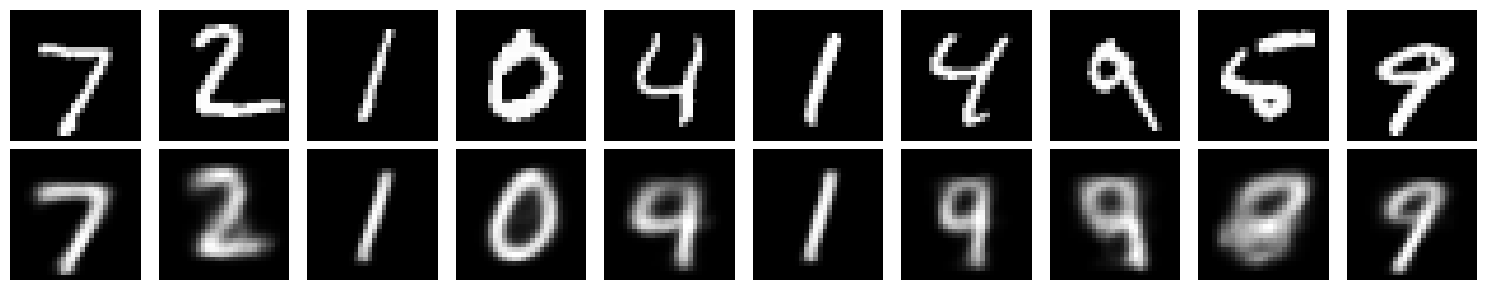

In [42]:
vae.eval()

x, _ = next(iter(test_loader))
x = x[:10].to(device)

with torch.no_grad():
    x_hat, _, _ = vae(x)

fig, axes = plt.subplots(2, 10, figsize=(15, 3))

for i in range(10):
    axes[0, i].imshow(x[i].cpu().squeeze(), cmap="gray")
    axes[0, i].axis("off")

    axes[1, i].imshow(x_hat[i].cpu().squeeze(), cmap="gray")
    axes[1, i].axis("off")

axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("VAE")

plt.tight_layout()
plt.show()

# **Visualisation de l'espace latent du VAE**

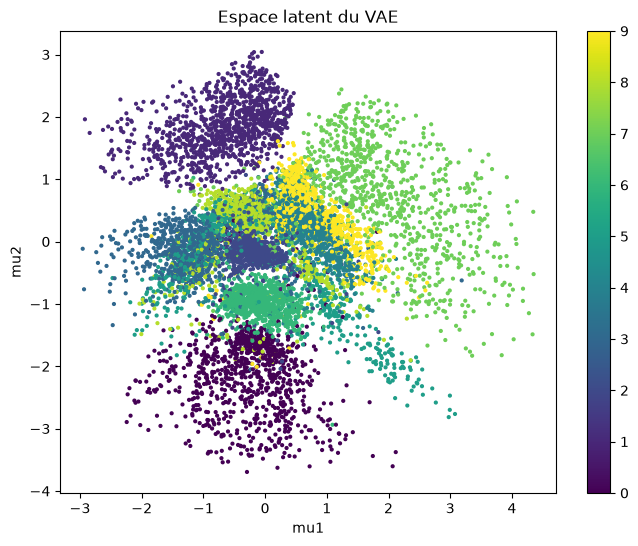

In [44]:
vae.eval()

mus = []
ys = []

with torch.no_grad():
    for x, y in test_loader:
        x = x.to(device)

        mu, logvar = vae.encode(x)

        mus.append(mu.cpu())
        ys.append(y)

MU = torch.cat(mus).numpy()
Y = torch.cat(ys).numpy()

plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    MU[:, 0],
    MU[:, 1],
    c=Y,
    s=4
)

plt.xlabel("mu1")
plt.ylabel("mu2")
plt.title("Espace latent du VAE")
plt.colorbar(scatter)
plt.show()

##  Générer de nouvelles images

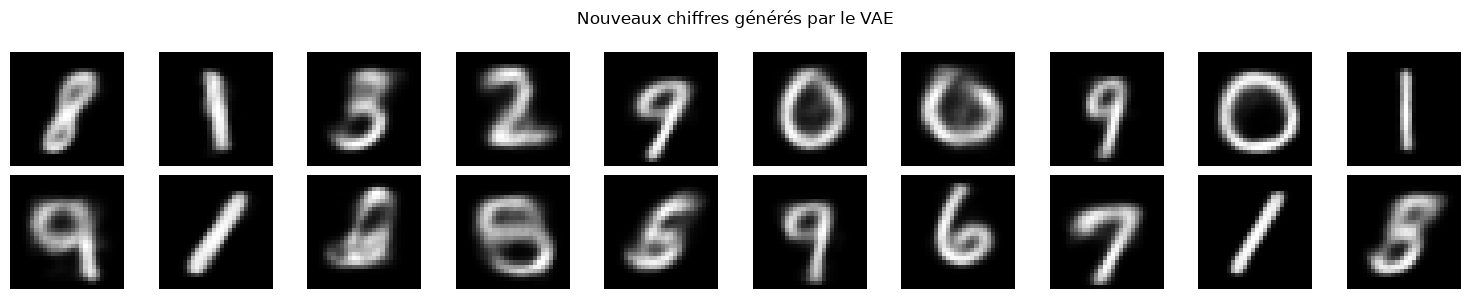

In [45]:
# Générer de nouvelles images
vae.eval()

with torch.no_grad():
    z = torch.randn(20, 2).to(device)
    samples = vae.decode(z).cpu()

fig, axes = plt.subplots(2, 10, figsize=(15, 3))

for i, ax in enumerate(axes.flat):
    ax.imshow(samples[i].squeeze(), cmap="gray")
    ax.axis("off")

plt.suptitle("Nouveaux chiffres générés par le VAE")
plt.tight_layout()
plt.show()

# Explorer manuellement l'espace latent


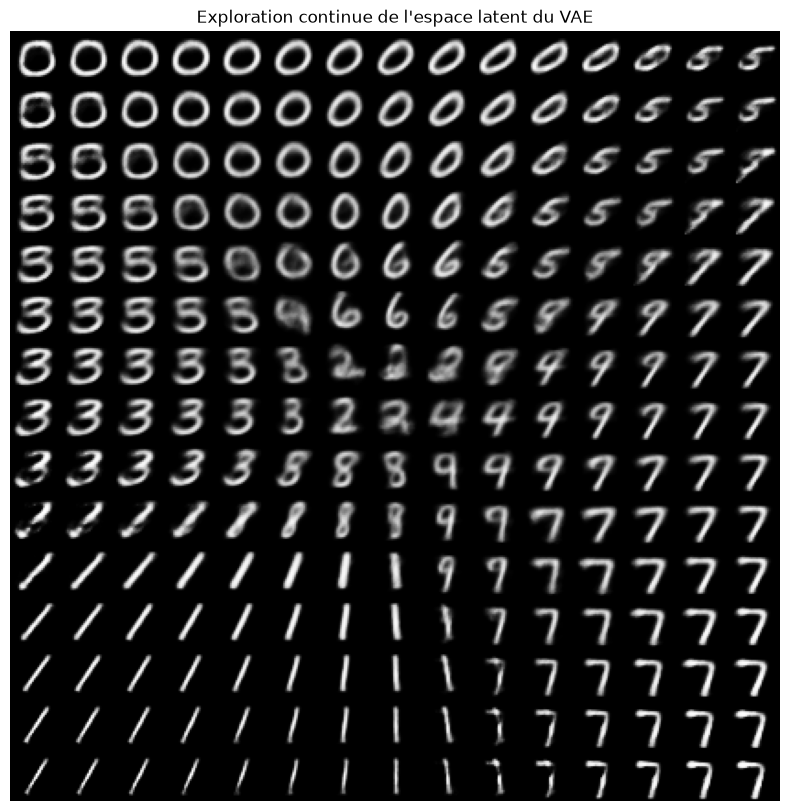

In [46]:
vae.eval()

grid_x = np.linspace(-3, 3, 15)
grid_y = np.linspace(-3, 3, 15)

figure = np.zeros((28 * 15, 28 * 15))

with torch.no_grad():
    for i, yi in enumerate(grid_y):
        for j, xi in enumerate(grid_x):

            z = torch.tensor(
                [[xi, yi]],
                dtype=torch.float32,
                device=device
            )

            x_hat = vae.decode(z)
            digit = x_hat.cpu().numpy()[0, 0]

            figure[
                i*28:(i+1)*28,
                j*28:(j+1)*28
            ] = digit

plt.figure(figsize=(10, 10))
plt.imshow(figure, cmap="gray")
plt.axis("off")
plt.title("Exploration continue de l'espace latent du VAE")
plt.show()